# Modul 6 — Simulasi Monte Carlo: "Kurangi jam gangguan Top-5"
**Pertanyaan manajemen:** jika kita berhasil mengurangi gangguan dari 5 penyebab terbesar sebesar 10–50%, berapa jam, ton katoda, dan nilai uang yang kita selamatkan — **dan seberapa pasti angka itu?**

Hasil satu angka ("hemat 40 jam") menyesatkan, karena data downtime kecil dan acak. Monte Carlo mengulang "tahun hipotetis" ribuan kali sehingga kita mendapat **rentang** dan **peluang**.

Langkah: (1) bangun simulator downtime dari Downtime_Log dan validasi, (2) terapkan skenario pengurangan, (3) ubah jam menjadi ton dan USD, (4) analisis ketidakpastian dan titik impas.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
S = pd.read_excel(XLSX, sheet_name=None)
h, log, harga = S["Data_Harian"], S["Downtime_Log"], S["Harga_Biaya"]
rng = np.random.default_rng(2026)
HARI = len(h)
tak = log[log.Kategori == "Tidak Terjadwal"]

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx


## 1. Siapa Top-5 dan berapa jam sebenarnya?

In [ ]:
par = tak.groupby("Penyebab").Durasi_Jam.agg(["count", "sum", "mean"]).sort_values("sum", ascending=False)
par.columns = ["Kejadian", "Jam", "Rata2_durasi"]
TOP5 = list(par.index[:5])
print(par.head(8).round(2))
print(f"\nTop-5: {par.Jam.iloc[:5].sum():.1f} jam = {par.Jam.iloc[:5].sum()/par.Jam.sum()*100:.1f}% dari {par.Jam.sum():.1f} jam tak terjadwal")

                             Kejadian   Jam  Rata2_durasi
Penyebab                                                 
Trip kompresor udara                7  34.0          4.86
Gangguan tuyere                     7  22.0          3.14
Kebocoran waste heat boiler         7  20.0          2.86
Gangguan demister                   5  18.0          3.60
Trip jaringan listrik               5  14.5          2.90
Gangguan casting wheel              3  12.0          4.00
Gangguan rectifier                  4  11.5          2.88
Kebocoran sel elektrolisis          2   9.0          4.50

Top-5: 108.5 jam = 61.1% dari 177.5 jam tak terjadwal


## 2. Simulator downtime (model generatif)
Untuk tiap penyebab *c* pada satu "periode 273 hari":
1. **Jumlah kejadian** ~ Poisson(λ_c). Karena λ_c sendiri tidak pasti (hanya 4–7 kejadian per penyebab), kita ambil λ_c dari distribusi **Gamma(n_c, 1)**: gambaran posterior Bayes dengan prior datar, yang rata-ratanya persis n_c. Ini menyebarkan ketidakpastian parameter ke hasil.
2. **Durasi tiap kejadian** diambil acak (dengan pengembalian) dari durasi historis penyebab itu (bootstrap).

Total jam penyebab *c* = jumlah durasi seluruh kejadian simulasi.

In [ ]:
N_SIM = 20000
dur = {c: tak.loc[tak.Penyebab == c, "Durasi_Jam"].values for c in par.index}
def simulate(causes, reps=N_SIM, rng=rng):
    """Mengembalikan: counts[reps, C] dan daftar durasi per simulasi per penyebab (lewat jumlah & list)."""
    counts = np.zeros((reps, len(causes)), int); events = []
    for j, c in enumerate(causes):
        lam = rng.gamma(len(dur[c]), 1.0, reps)          # laju kejadian per periode 273 hari
        counts[:, j] = rng.poisson(lam)
    return counts

causes_all = list(par.index)
counts = simulate(causes_all)
# durasi tiap kejadian: gambar sekali dengan urutan tetap supaya skenario bisa memakai ANGKA ACAK YANG SAMA (common random numbers)
max_n = counts.max(axis=0)
dur_draws = {c: rng.choice(dur[c], size=(N_SIM, max(m, 1))) for c, m in zip(causes_all, max_n)}
def hours_by_cause(counts, dur_draws):
    H = np.zeros(counts.shape)
    for j, c in enumerate(causes_all):
        mask = np.arange(dur_draws[c].shape[1])[None, :] < counts[:, j][:, None]
        H[:, j] = (dur_draws[c] * mask).sum(axis=1)
    return H
H0 = hours_by_cause(counts, dur_draws)          # jam per penyebab, tanpa intervensi
tot0 = H0.sum(axis=1)
print(f"Validasi simulator: rata-rata total jam tak terjadwal = {tot0.mean():.1f}  (aktual {par.Jam.sum():.1f}); 90% rentang simulasi [{np.percentile(tot0,5):.0f}, {np.percentile(tot0,95):.0f}]")
idx5 = [causes_all.index(c) for c in TOP5]
print(f"Top-5: simulasi {H0[:, idx5].sum(1).mean():.1f} jam vs aktual {par.Jam.iloc[:5].sum():.1f} jam")

Validasi simulator: rata-rata total jam tak terjadwal = 177.1  (aktual 177.5); 90% rentang simulasi [122, 240]
Top-5: simulasi 108.1 jam vs aktual 108.5 jam


**Mengapa validasi?** Simulator yang tidak mereproduksi data aktual tidak layak dipakai untuk ramalan. Jika rata-rata simulasi jauh dari angka aktual, ada kesalahan model.

## 3. Skenario pengurangan
Dua mekanisme berbeda yang sering dicampuradukkan:
- **Frekuensi** (pencegahan): tiap kejadian Top-5 *dibatalkan* dengan peluang r. Dipakai binomial thinning.
- **Durasi** (perbaikan lebih cepat): durasi tiap kejadian dikali (1 − r).

Keduanya mengurangi jam Top-5 rata-rata sebesar r, tetapi **ketidakpastiannya berbeda**.

In [ ]:
def scenario(r, mode):
    H1 = H0.copy()
    if mode == "durasi":
        H1[:, idx5] = H0[:, idx5] * (1 - r)
    else:                                                       # frekuensi: batalkan sebagian kejadian
        for j in idx5:
            c = causes_all[j]; keep = rng.random(dur_draws[c].shape) > r
            mask = np.arange(dur_draws[c].shape[1])[None, :] < counts[:, j][:, None]
            H1[:, j] = (dur_draws[c] * mask * keep).sum(axis=1)
    return (H0 - H1).sum(axis=1)                                # jam yang dihemat (≥ 0 pada frekuensi)

hasil = []
for mode in ["frekuensi", "durasi"]:
    for r in [0.1, 0.2, 0.3, 0.4, 0.5]:
        s = scenario(r, mode)
        hasil.append(dict(mode=mode, reduksi=f"{int(r*100)}%", jam_rata2=s.mean(), P5=np.percentile(s, 5), P95=np.percentile(s, 95)))
print(pd.DataFrame(hasil).round(1).to_string(index=False))

     mode reduksi  jam_rata2   P5  P95
frekuensi     10%       10.8  1.0 24.5
frekuensi     20%       21.6  6.0 41.5
frekuensi     30%       32.5 12.5 57.0
frekuensi     40%       43.3 19.0 72.0
frekuensi     50%       54.0 26.5 87.0
   durasi     10%       10.8  6.4 16.0
   durasi     20%       21.6 12.7 32.1
   durasi     30%       32.4 19.1 48.2
   durasi     40%       43.2 25.4 64.2
   durasi     50%       54.0 31.8 80.2


## 4. Dari jam ke ton dan USD
- **Ton per jam operasi** = total katoda ÷ total jam operasi, di-*bootstrap* dari hari-hari aktual (ketidakpastian laju).
- **Harga LME**: log-normal dengan rata-rata harga selama periode dan volatilitas dari data `Harga_Biaya`.
- Nilai di sini adalah **pendapatan kotor** katoda tambahan, bukan laba (belum dikurangi biaya konsentrat, energi, dll).

In [ ]:
rate_boot = np.empty(N_SIM)
kat, jop = h.Katoda_Cu_t.values, h.Jam_Operasi.values
for i in range(N_SIM):
    ix = rng.integers(0, HARI, HARI); rate_boot[i] = kat[ix].sum() / jop[ix].sum()
print(f"Ton per jam operasi: {kat.sum()/jop.sum():.2f} (bootstrap 90%: {np.percentile(rate_boot,5):.2f}–{np.percentile(rate_boot,95):.2f})")

lme = harga.LME_Cu_USD_per_t.values
vol_harian = np.std(np.diff(np.log(lme)), ddof=1)
sigma_periode = vol_harian * np.sqrt(HARI)
price = lme.mean() * np.exp(rng.normal(-0.5 * sigma_periode**2, sigma_periode, N_SIM))
print(f"Harga LME rata-rata {lme.mean():,.0f} USD/t | volatilitas periode {sigma_periode*100:.1f}%")

R = 0.30                                                       # skenario utama: kurangi 30% lewat pencegahan (frekuensi)
jam = scenario(R, "frekuensi"); ton = jam * rate_boot; usd = ton * price
ringkas = pd.DataFrame({"Jam": jam, "Ton katoda": ton, "USD juta": usd / 1e6})
print(f"\nSKENARIO UTAMA: kurangi gangguan Top-5 sebesar {int(R*100)}% (frekuensi)")
print(ringkas.describe(percentiles=[.05, .5, .95]).loc[["mean", "5%", "50%", "95%"]].round(2))

Ton per jam operasi: 25.12 (bootstrap 90%: 25.01–25.23)
Harga LME rata-rata 10,200 USD/t | volatilitas periode 11.4%

SKENARIO UTAMA: kurangi gangguan Top-5 sebesar 30% (frekuensi)
       Jam  Ton katoda  USD juta
mean  32.5      816.53      8.33
5%    12.5      313.18      3.08
50%   31.0      782.59      7.93
95%   57.0     1434.79     15.02


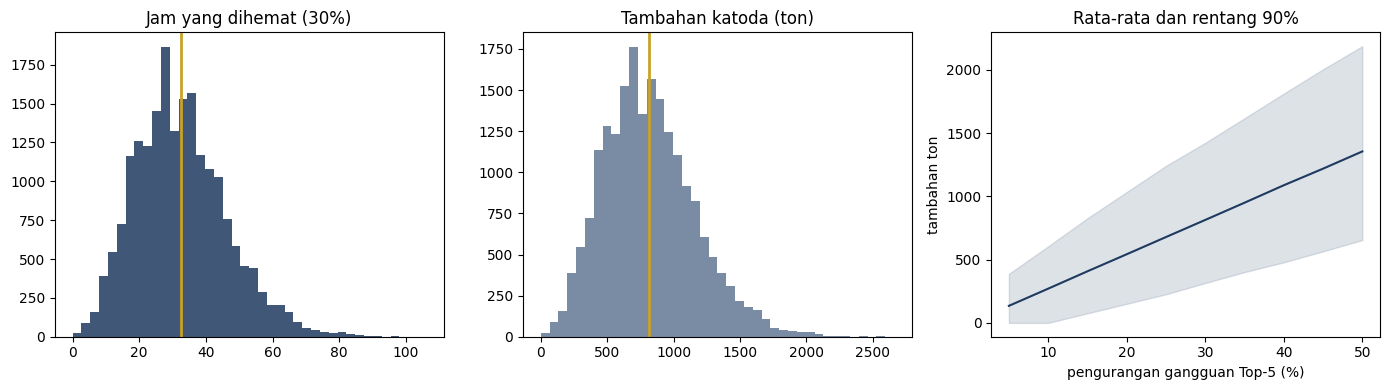

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].hist(jam, bins=40, color="#1F3A5F", alpha=.85); ax[0].axvline(jam.mean(), color="#C9A227", lw=2); ax[0].set_title("Jam yang dihemat (30%)")
ax[1].hist(ton, bins=40, color="#7A8CA3"); ax[1].axvline(ton.mean(), color="#C9A227", lw=2); ax[1].set_title("Tambahan katoda (ton)")
rs = np.linspace(0.05, 0.5, 10); med, lo, hi = [], [], []
for r in rs:
    t_ = scenario(r, "frekuensi") * rate_boot; med.append(t_.mean()); lo.append(np.percentile(t_, 5)); hi.append(np.percentile(t_, 95))
ax[2].plot(rs * 100, med, color="#1F3A5F"); ax[2].fill_between(rs * 100, lo, hi, alpha=.25, color="#7A8CA3")
ax[2].set_xlabel("pengurangan gangguan Top-5 (%)"); ax[2].set_ylabel("tambahan ton"); ax[2].set_title("Rata-rata dan rentang 90%")
plt.tight_layout(); plt.show()

## 5. Pertanyaan keputusan: berapa peluang untung?
**Asumsi penting:** (1) produksi yang hilang akibat downtime benar-benar bisa diproduksi (konsentrat tersedia, tidak ada batas kapasitas lain); (2) nilai dihitung pada pendapatan kotor.
Misalkan program pencegahan memakan biaya tetap **BIAYA_PROGRAM** (angka contoh; ganti dengan estimasi nyata). Titik impas terjadi bila nilai tambahan katoda > biaya.

In [ ]:
BIAYA_PROGRAM_USD = 6_000_000                                    # CONTOH: sesuaikan dengan estimasi nyata
p_untung = (usd > BIAYA_PROGRAM_USD).mean()
print(f"Biaya program contoh: {BIAYA_PROGRAM_USD:,.0f} USD")
print(f"Peluang nilai tambahan katoda > biaya: {p_untung*100:.0f}%")
print(f"Rata-rata nilai: {usd.mean():,.0f} USD  | 90% rentang [{np.percentile(usd,5):,.0f}, {np.percentile(usd,95):,.0f}]")
be = np.percentile(usd, np.arange(0, 101, 5)); print("Persentil nilai (juta USD):", (be / 1e6).round(2))

Biaya program contoh: 6,000,000 USD
Peluang nilai tambahan katoda > biaya: 71%
Rata-rata nilai: 8,333,886 USD  | 90% rentang [3,076,798, 15,018,215]
Persentil nilai (juta USD): [ 0.    3.08  3.98  4.63  5.18  5.67  6.13  6.6   7.05  7.47  7.93  8.37
  8.85  9.37  9.89 10.53 11.23 12.11 13.22 15.02 32.55]


## 6. Penyebab mana yang paling layak diprioritaskan?
Hemat jam dengan menghilangkan 30% kejadian **per penyebab saja** (bukan seluruh Top-5):

In [ ]:
rows = []
for j in idx5:
    c = causes_all[j]; keep = rng.random(dur_draws[c].shape) > 0.30
    mask = np.arange(dur_draws[c].shape[1])[None, :] < counts[:, j][:, None]
    saved = H0[:, j] - (dur_draws[c] * mask * keep).sum(1)
    rows.append(dict(Penyebab=c, Jam_aktual=par.loc[c, "Jam"], Hemat_jam_rata2=saved.mean(), P5=np.percentile(saved, 5), P95=np.percentile(saved, 95)))
print(pd.DataFrame(rows).sort_values("Hemat_jam_rata2", ascending=False).round(1).to_string(index=False))

                   Penyebab  Jam_aktual  Hemat_jam_rata2  P5  P95
       Trip kompresor udara        34.0             10.1 0.0 27.0
            Gangguan tuyere        22.0              6.5 0.0 16.0
Kebocoran waste heat boiler        20.0              5.9 0.0 16.0
          Gangguan demister        18.0              5.4 0.0 17.0
      Trip jaringan listrik        14.5              4.4 0.0 12.0


**Kesimpulan modul 6.**

*   Simulator tervalidasi: rata-rata 177,1 jam vs aktual 177,5 jam.
*   Skenario mengurangi frekuensi lima penyebab teratas sebesar 30% menghemat sekitar 32,5 jam, atau 817 t dan 8,3 juta USD (90% rentang 3,1–15,0 juta). Peluang nilainya melebihi biaya program contoh 6 juta USD adalah 71%.
*   Mengurangi frekuensi atau durasi punya rata-rata sama, tetapi ketidakpastian frekuensi jauh lebih lebar.


